# UC2 · Jalon 2 — Voir les produits : CNN et auto-encodeur
 **Groupe 13 · Master SDIA-2 · ENSET Mohammedia**  
 Agrigah Aya · AARAB Mustapha · Toubani Badr Eddine

 Remplacer la représentation visuelle du MLP par des convolutions et comparer des goulots pour le rejet hors catalogue.

 **Données officielles :** les quatre fichiers NPZ du dossier `Use Cases.rar`,
 partitions imposées conservées. Fashion-MNIST fournit les images ; descriptions,
 prix, boutique B et sessions sont des données pédagogiques simulées. Nous
 n'affirmons pas entraîner un système de production sur de vraies ventes.

 Le projet Kaggle antérieur reste dans `annexes/historique_kaggle`. Il ne possède
 pas les prix/sessions ni les partitions imposées. Ses scores ne sont pas mêlés
 aux résultats de cette remise. Le groupe a utilisé une assistance IA pour le
 code, la rédaction et les contrôles ; les sorties chiffrées sont calculées.

## Exécution et fichiers à conserver
 1. Décompresser **toute** l'archive, garder `data_UC2/` et `src/` avec les notebooks.
 2. Suivre le README pour l'environnement Python 3.12, TensorFlow 2.20 / Keras 3.11.3.
 3. VS Code : extensions Python/Jupyter, choisir `.venv-uc2` comme noyau. Colab :
    GPU facultatif, placer le dossier complet dans Drive puis ouvrir ce notebook.
 4. Exécuter dans l'ordre. Les modèles livrés sont réutilisés lorsqu'ils sont compatibles.
    Pour une nouvelle exécution indépendante, renseigner `RUN_LABEL` ci-dessous.
 5. Sauvegarder le notebook avec sorties. Les modèles, courbes, journal et décisions
    s'enregistrent dans `artifacts/jalonN/` (ou `reruns/RUN_LABEL/jalonN/`).

 Tous les réglages précèdent l'ouverture du test. La session finale est figée par
 empreintes des poids et de la configuration. Une relance lit les résultats
 finalisés. Ne pas modifier un modèle/seuil après accès au test pour améliorer
 artificiellement le score. Les comparateurs fixés sont évalués dans cette même
 session finale. Le temps mesuré dépend du matériel et exclut l'installation.

In [1]:
import os,sys,subprocess
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL","2")
assert (3,10)<=sys.version_info[:2]<=(3,13), "Utiliser Python 3.12."
# Configuration facultative avant exécution, pas après le test.
PROJECT_DIR = None  # Colab : "/content/drive/MyDrive/GroupeXX_UC2"
RUN_LABEL = ""      # ex. "reproduction_cpu" pour un nouveau dossier de résultats
if PROJECT_DIR:
    ROOT=Path(PROJECT_DIR).expanduser().resolve()
else:
    candidates=[Path.cwd(),Path.cwd().parent]
    ROOT=next((p for p in candidates if (p/"data_UC2/uc2_catalogueA.npz").exists()),None)
    if ROOT is None:raise FileNotFoundError("Ouvrir le dossier complet de l'archive ou définir PROJECT_DIR.")
sys.path.insert(0,str(ROOT/"src"))
from uc2_utils import *
from tensorflow.keras import layers
CFG={'epochs': 20, 'batch': 128, 'patience': 4, 'cnn_selection': 'macro F1 val', 'ae_selection': 'synthetic validation proxy AUC', 'fpr': 0.05, 'proxy_seed': 142, 'codes': [None, 8, 32, 128]}
OUT,ENV,DATA_SHA=initialise(ROOT,2,CFG,RUN_LABEL)
display(pd.DataFrame([ENV]).T.rename(columns={0:"Valeur"}))
print("Dossier :",ROOT,"| résultats :",OUT)
print("GPU :",ENV["devices"] or "CPU (4 threads)")

Dossier : /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2 | résultats : /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2/artifacts/jalon2
GPU : CPU (4 threads)


,Valeur
python,"3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 2..."
platform,Linux-6.18.44-x86_64-with-glibc2.39
tensorflow,2.20.0
keras,3.11.3
devices,[]
cpu_threads,4
seed,42
numpy,2.3.5
pandas,2.2.3
scipy,1.17.0


## 1. Protocole de comparaison et cas délicat du fichier OOD
 La branche texte reste le sac de **169 mots** de train A. Les CNN conservent
 même tête de fusion, optimiseur, graine et budget. Facteurs : bloc supplémentaire,
 pooling moyen, puis L2+dropout comme famille de régularisation. Aucun effet
 individuel de L2 versus dropout n'est revendiqué dans cette dernière variante.

 **`uc2_ood_test.npz` n'a aucune partition de validation.** Pour respecter les
 consignes, on ne peut pas choisir le goulot en regardant l'AUC de ce test.
 Nous préannonçons donc des *anomalies de validation synthétiques* (bruit,
 motifs géométriques, carreaux d'images permutés) et sélectionnons les AE sur leur
 AUC dans ce proxy. Elles ne sont pas les 300 anomalies du fichier test.
 Le score réel de 1 300 soumissions est calculé une seule fois pour l'AE retenu.
 Cette différence de distribution est une limite importante, pas un moyen de
 prétendre connaître la validation OOD officielle.

 Validation A (4 000) : 2 000 pour arrêt des AE, 1 000 pour quantile ID à 95%,
 1 000 ID pour évaluation du proxy. Ce découpage interne ne change ni train ni
 test imposés. Le CNN utilise les 4 000 annonces val pour F1. Le seuil est figé
 sur calibration, le rejet est `MSE > seuil`, sans recalibrage sur le test.

Rôles val : 2000 1000 1000 | anomalies proxy : 900


,split,rows,empty_descriptions,median_price_dh,min_price_dh,max_price_dh
0,train,20000,1043,270.0,30.0,2735.0
1,val,4000,225,265.0,35.0,2585.0


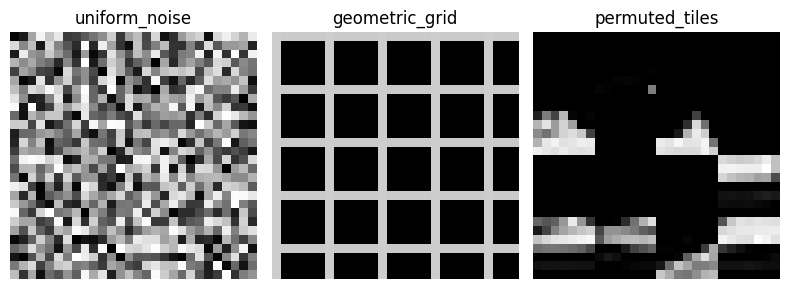

In [2]:
from sklearn.model_selection import train_test_split
A=load_catalogue(ROOT,'A');display(catalogue_audit(A));BOW=fit_bow(A)
IMG={s:image_input(A,s) for s in ['train','val']};MOTS={s:bow_input(BOW,A,s) for s in ['train','val']}
Y={s:A['categorie_'+s] for s in ['train','val']}
ind=np.arange(len(IMG['val']))
RECON,rest=train_test_split(ind,test_size=.5,random_state=42,stratify=Y['val'])
CALIB,DETECT=train_test_split(rest,test_size=.5,random_state=42,stratify=Y['val'][rest])
assert not set(RECON)&set(CALIB) and not set(CALIB)&set(DETECT) and not set(RECON)&set(DETECT)
write_json(OUT/'validation_roles.json',{'reconstruction':RECON,'calibration':CALIB,'detection':DETECT})
write_json(OUT/'vocabulary.json',BOW.vocabulary_)
def make_validation_proxies():
    rng=np.random.default_rng(CFG['proxy_seed']);out=[];kinds=[]
    for j in range(900):
        if j%3==0:
            x=rng.uniform(0,1,(28,28)).astype('float32');kind='uniform_noise'
        elif j%3==1:
            x=np.zeros((28,28),dtype='float32');stride=int(rng.integers(2,7))
            x[::stride,:]=rng.uniform(.4,1.);x[:,::stride]=rng.uniform(.4,1.);kind='geometric_grid'
        else:
            raw=IMG['train'][int(rng.integers(len(IMG['train'])))][...,0]
            tiles=raw.reshape(4,7,4,7).transpose(0,2,1,3).reshape(16,7,7)
            x=tiles[rng.permutation(16)].reshape(4,4,7,7).transpose(0,2,1,3).reshape(28,28);kind='permuted_tiles'
        out.append(x[...,None]);kinds.append(kind)
    return np.stack(out),np.array(kinds)
PROXY,PROXY_KIND=make_validation_proxies()
np.savez_compressed(OUT/'synthetic_validation_proxies.npz',X=PROXY,kind=PROXY_KIND)
print('Rôles val :',len(RECON),len(CALIB),len(DETECT),'| anomalies proxy :',len(PROXY))
fig,axes=plt.subplots(1,3,figsize=(8,3))
for i,ax in enumerate(axes):ax.imshow(PROXY[i,...,0],cmap='gray',vmin=0,vmax=1);ax.set_title(PROXY_KIND[i]);ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'validation_proxy_examples.png',dpi=150);plt.show();plt.close(fig)

## 2. Dimensions, paramètres et champ réceptif
 CNN théorique image seule : Conv32 same 28×28×32 (320 paramètres), pool 14×14×32,
 Conv64 **valid** 12×12×64 (18 496), pool 6×6×64, Flatten2304, Dense128 (295 040),
 Dense10 (1 290), total **315 146**. Le second padding n'est pas spécifié dans le
 PDF : avec `same`, total **421 642**. On vérifie les deux interprétations.

 Champ local : `r←r+(k−1)j`, `j←js`. Conv/pool/conv/pool donnent 3,4,8,10 pixels,
 saut final 4. Dense agrège toute la carte : le champ local n'est pas le champ de
 toute la prédiction. Le CNN multimodal ajoute sa fusion avec 169 mots, donc son
 total de paramètres diffère de celui du réseau théorique image seule.

 AE de départ : 28→14→7, code 7×7×32=1 568, supérieur aux 784 pixels. Il n'a pas
 de goulot dimensionnel étroit. Un code dense 8 réduit la représentation mais
 ajoute des matrices denses : compression et nombre de poids sont distincts.

Padding valid
Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼───────

,model,macro_f1,accuracy,parameters,trainable_parameters,seconds,best_epoch,local_rf
0,MLP_reference,0.944427,0.94350,246794,246794,11.951934,14,NaN
1,CNN_base,0.963550,0.96325,392714,392714,81.560872,15,10.0
2,CNN_deep,0.960881,0.96050,202346,202346,82.382048,14,22.0
3,CNN_avgpool,0.956223,0.95600,392714,392714,66.189468,13,10.0
4,CNN_regularized,0.959606,0.95925,392714,392714,74.488006,14,10.0


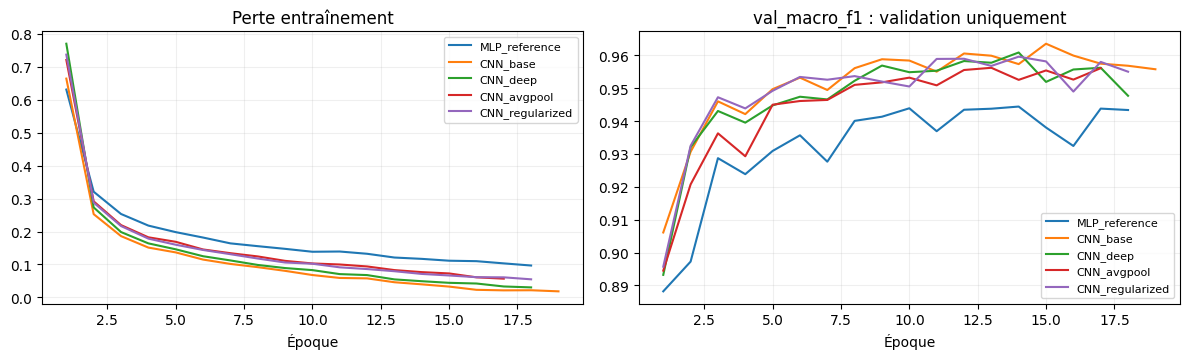

In [3]:
def theoretical_cnn(padding='valid'):
    return keras.Sequential([layers.Input((28,28,1)),layers.Conv2D(32,3,padding='same',activation='relu'),
        layers.MaxPooling2D(),layers.Conv2D(64,3,padding=padding,activation='relu'),layers.MaxPooling2D(),
        layers.Flatten(),layers.Dense(128,activation='relu'),layers.Dense(10,activation='softmax')])
for padding,total in [('valid',315146),('same',421642)]:
    m=theoretical_cnn(padding);assert m.count_params()==total;print('Padding',padding);m.summary()
def classifier(name):
    image=keras.Input((28,28,1),name='image');mots=keras.Input((169,),name='mots')
    if name=='MLP_reference':x=layers.Flatten()(image);x=layers.Concatenate()([x,mots])
    else:
        regular=keras.regularizers.l2(1e-4) if name=='CNN_regularized' else None
        Pool=layers.AveragePooling2D if name=='CNN_avgpool' else layers.MaxPooling2D
        x=layers.Conv2D(32,3,padding='same',activation='relu',kernel_regularizer=regular)(image);x=Pool(2)(x)
        x=layers.Conv2D(64,3,padding='valid',activation='relu',kernel_regularizer=regular)(x);x=Pool(2)(x)
        if name=='CNN_deep':x=layers.Conv2D(96,3,activation='relu')(x);x=Pool(2)(x)
        x=layers.Flatten()(x);x=layers.Dense(128,activation='relu')(x)
        if name=='CNN_regularized':x=layers.Dropout(.3)(x)
        x=layers.Concatenate()([x,mots])
    x=layers.Dense(256,activation='relu')(x);x=layers.Dropout(.3)(x);out=layers.Dense(10,activation='softmax')(x)
    m=keras.Model({'image':image,'mots':mots},out);m.compile(keras.optimizers.Adam(1e-3),'sparse_categorical_crossentropy',metrics=['accuracy']);return m
CNN_NAMES=['MLP_reference','CNN_base','CNN_deep','CNN_avgpool','CNN_regularized']
CLASS_MODELS={};class_rows=[]
INP={s:{'image':IMG[s],'mots':MOTS[s]} for s in ['train','val']}
for name in CNN_NAMES:
    m,info=fit_model(OUT,name,lambda n=name:classifier(n),INP['train'],Y['train'],INP['val'],Y['val'],epochs=CFG['epochs'],
        monitor='val_macro_f1',mode='max',evaluator=lambda p:{'val_macro_f1':classifier_metrics(Y['val'],p)['macro_f1']})
    CLASS_MODELS[name]=m;rf=None if name=='MLP_reference' else 22 if name=='CNN_deep' else 10
    class_rows.append(validation_row(OUT,name,info,classifier_metrics(Y['val'],predict(m,INP['val'])),local_rf=rf))
CLASS_VAL=write_table(OUT,'classification_validation',class_rows)
SELECTED_CNN=CLASS_VAL[CLASS_VAL.model!='MLP_reference'].sort_values(['macro_f1','parameters'],ascending=[False,True]).iloc[0].model
learning_curves(OUT,CNN_NAMES,'val_macro_f1','cnn_learning.png')
write_json(OUT/'theory_checks.json',{'image_only_valid_parameters':315146,'image_only_same_parameters':421642,
    'local_rf_base':10,'local_rf_deep':22,'encoder_code_units':1568,'input_pixels':784})

In [4]:
ref=per_class(Y['val'],predict(CLASS_MODELS['MLP_reference'],INP['val']))
win=per_class(Y['val'],predict(CLASS_MODELS[SELECTED_CNN],INP['val']))
gains=ref.rename(columns={'f1':'mlp_f1'});gains['cnn_f1']=win.f1;gains['gain']=gains.cnn_f1-gains.mlp_f1
display(gains);gains.to_csv(OUT/'per_class_validation_gains.csv',index=False)

,category,mlp_f1,support,cnn_f1,gain
0,T-shirt/top,0.904943,393,0.930693,0.025750
1,Pantalon,0.990050,404,0.993789,0.003739
2,Pull,0.894063,406,0.934809,0.040746
3,Robe,0.962241,416,0.971154,0.008913
4,Manteau,0.914141,417,0.948379,0.034238
5,Sandale,0.978882,405,0.987685,0.008803
6,Chemise,0.864799,405,0.902655,0.037856
7,Basket,0.970297,400,0.988764,0.018467
8,Sac,0.988571,352,0.990071,0.001499
9,Bottine,0.976280,402,0.987500,0.011220


Essai fourni 5 époques, hors sélection à budget commun : 18817 paramètres
CNN CNN_base | AE AE_128 | seuil validation 0.017127474769949913


,model,proxy_auc,recall_at_val5pct,proxy_test_id_fpr,false_rejects,proxy_accepted_ood,id_rows,ood_rows,threshold,calibration_fpr,parameters,trainable_parameters,seconds,best_epoch,code_units
0,AE_none,0.974288,0.891111,0.063,63,98,1000,900,0.002193,0.049,18817,18817,61.481174,20,1568
1,AE_8,0.995743,0.982222,0.067,67,16,1000,900,0.035647,0.049,45481,45481,63.470362,20,8
2,AE_32,0.996668,0.986667,0.059,59,12,1000,900,0.024924,0.049,120769,120769,69.957456,20,32
3,AE_128,0.996949,0.984444,0.055,55,14,1000,900,0.017127,0.049,421921,421921,69.112111,20,128


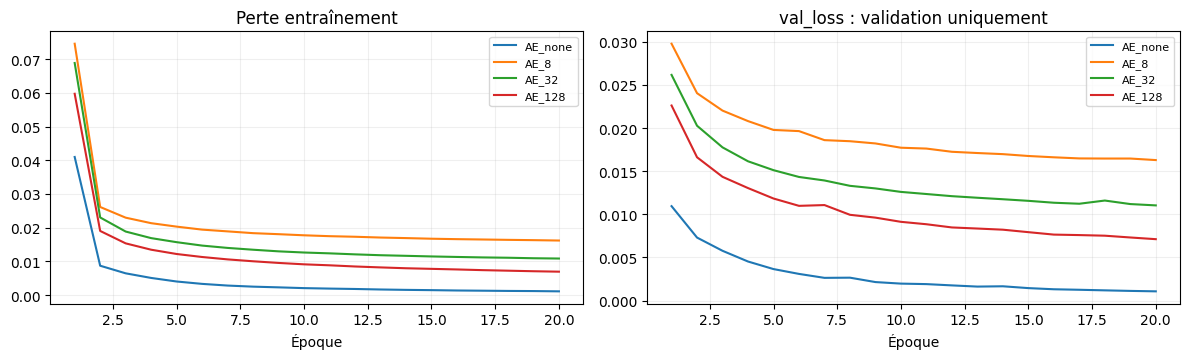

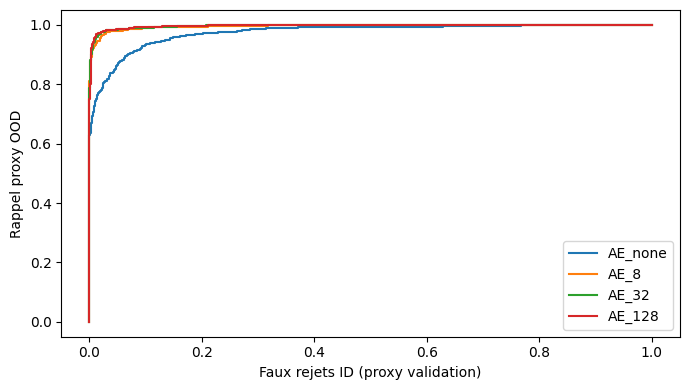

In [5]:
def autoencoder(code_units=None):
    inp=keras.Input((28,28,1));x=layers.Conv2D(16,3,strides=2,padding='same',activation='relu')(inp)
    x=layers.Conv2D(32,3,strides=2,padding='same',activation='relu')(x)
    if code_units is not None:
        x=layers.Flatten()(x);x=layers.Dense(code_units,activation='relu',name='code')(x)
        x=layers.Dense(1568,activation='relu')(x);x=layers.Reshape((7,7,32))(x)
    x=layers.Conv2DTranspose(32,3,strides=2,padding='same',activation='relu')(x)
    x=layers.Conv2DTranspose(16,3,strides=2,padding='same',activation='relu')(x)
    out=layers.Conv2D(1,3,padding='same',activation='sigmoid')(x)
    m=keras.Model(inp,out);m.compile(keras.optimizers.Adam(1e-3),'mse');return m
def mse_scores(m,x):return np.mean((predict(m,x)-x)**2,axis=(1,2,3))
starter,starter_info=fit_model(OUT,'AE_starter_5epochs',autoencoder,IMG['train'],IMG['train'],IMG['val'][RECON],IMG['val'][RECON],epochs=5)
print('Essai fourni 5 époques, hors sélection à budget commun :',starter_info['parameters'],'paramètres')
AE_MODELS={};ae_rows=[];AE_SCORES={}
for units in CFG['codes']:
    name='AE_none' if units is None else f'AE_{units}'
    m,info=fit_model(OUT,name,lambda k=units:autoencoder(k),IMG['train'],IMG['train'],IMG['val'][RECON],IMG['val'][RECON],epochs=CFG['epochs'])
    calibration=mse_scores(m,IMG['val'][CALIB]);tau=float(np.quantile(calibration,.95,method='higher'))
    idscore=mse_scores(m,IMG['val'][DETECT]);oodscore=mse_scores(m,PROXY)
    yy=np.r_[np.zeros(len(idscore)),np.ones(len(oodscore))];ss=np.r_[idscore,oodscore]
    metrics=binary_detection(yy,ss,tau)
    metrics={('proxy_'+k if k in ['auc','test_id_fpr','accepted_ood'] else k):v for k,v in metrics.items()}
    metrics['calibration_fpr']=float(np.mean(calibration>tau))
    AE_MODELS[name]=m;AE_SCORES[name]=(idscore,oodscore)
    ae_rows.append(validation_row(OUT,name,info,metrics,code_units=1568 if units is None else units))
AE_VAL=write_table(OUT,'autoencoder_validation_proxy',ae_rows)
SELECTED_AE=AE_VAL.sort_values(['proxy_auc','recall_at_val5pct','parameters'],ascending=[False,False,True]).iloc[0].model
THRESHOLD=float(AE_VAL.set_index('model').loc[SELECTED_AE,'threshold'])
print('CNN',SELECTED_CNN,'| AE',SELECTED_AE,'| seuil validation',THRESHOLD)
learning_curves(OUT,list(AE_MODELS),'val_loss','ae_learning.png')
fig,ax=plt.subplots(figsize=(7,4))
for name,(ids,ods) in AE_SCORES.items():
    fpr,tpr,_=roc_curve(np.r_[np.zeros(len(ids)),np.ones(len(ods))],np.r_[ids,ods]);ax.plot(fpr,tpr,label=name)
ax.set(xlabel='Faux rejets ID (proxy validation)',ylabel='Rappel proxy OOD');ax.legend();fig.tight_layout();fig.savefig(OUT/'ae_validation_proxy_roc.png',dpi=150);plt.show();plt.close(fig)

## 3. Test final de classification et de soumissions
 Les autres goulots ne sont pas évalués sur le fichier test pour éviter une
 sélection après coup. Leur comparaison AUC/rappel se trouve dans la validation
 proxy ci-dessus. La session suivante évalue CNN retenu, MLP fixé, AE retenu.

In [6]:
selection={'cnn':SELECTED_CNN,'ae':SELECTED_AE,'threshold':round(THRESHOLD,8),
           'ae_selection_scope':'synthetic proxies only','fixed_comparator':'MLP_reference',
           'models':[SELECTED_CNN,SELECTED_AE,'MLP_reference']}
def evaluate_final():
    at=load_catalogue(ROOT,'A',('test',));x={'image':image_input(at,'test'),'mots':bow_input(BOW,at,'test')}
    cnn=predict(CLASS_MODELS[SELECTED_CNN],x);mlp=predict(CLASS_MODELS['MLP_reference'],x)
    with np.load(ROOT/'data_UC2/uc2_ood_test.npz',allow_pickle=False) as o:
        ox=o['X'][...,None].astype('float32')/255.;oy=o['hors_catalogue']
    assert len(ox)==1300 and np.sum(oy)==300
    score=mse_scores(AE_MODELS[SELECTED_AE],ox)
    np.savez_compressed(OUT/'test_predictions.npz',cnn_probability=cnn,mlp_probability=mlp,category_true=at['categorie_test'],
        ood_score=score,ood_true=oy)
    return {'cnn':{'model':SELECTED_CNN,**classifier_metrics(at['categorie_test'],cnn)},
        'mlp_reference':classifier_metrics(at['categorie_test'],mlp),
        'detector':{'model':SELECTED_AE,**binary_detection(oy,score,THRESHOLD)}}
TEST=test_once(OUT,selection,evaluate_final);display(pd.DataFrame(TEST).T)

Session finale déjà terminée : lecture des résultats figés, sans nouvelle inférence test.


,model,macro_f1,accuracy,auc,recall_at_val5pct,test_id_fpr,false_rejects,accepted_ood,id_rows,ood_rows,threshold
cnn,CNN_base,0.952169,0.952,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mlp_reference,NaN,0.931578,0.930833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
detector,AE_128,NaN,NaN,0.828683,0.466667,0.046,46,160,1000,300,0.017127


Catalogue rejeté à tort : 46 cas au total
Hors catalogue accepté : 160 cas au total


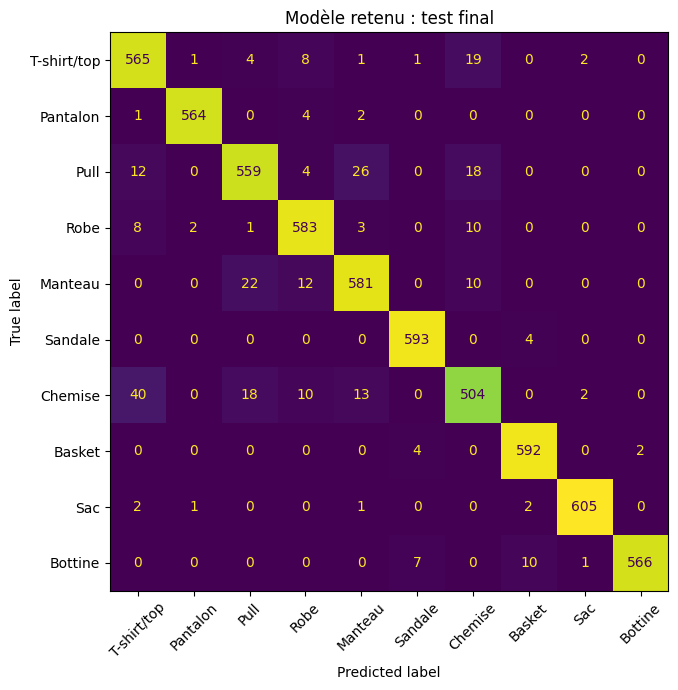

,category,mlp_f1,support,cnn_f1,gain
0,T-shirt/top,0.909245,601,0.919447,0.010202
1,Pantalon,0.986807,571,0.990342,0.003535
2,Pull,0.874719,619,0.914146,0.039427
3,Robe,0.936378,607,0.949511,0.013133
4,Manteau,0.881702,625,0.928115,0.046413
5,Sandale,0.968881,597,0.986689,0.017807
6,Chemise,0.848434,587,0.878049,0.029615
7,Basket,0.962357,598,0.981758,0.019401
8,Sac,0.976821,611,0.990991,0.014170
9,Bottine,0.970435,584,0.982639,0.012204


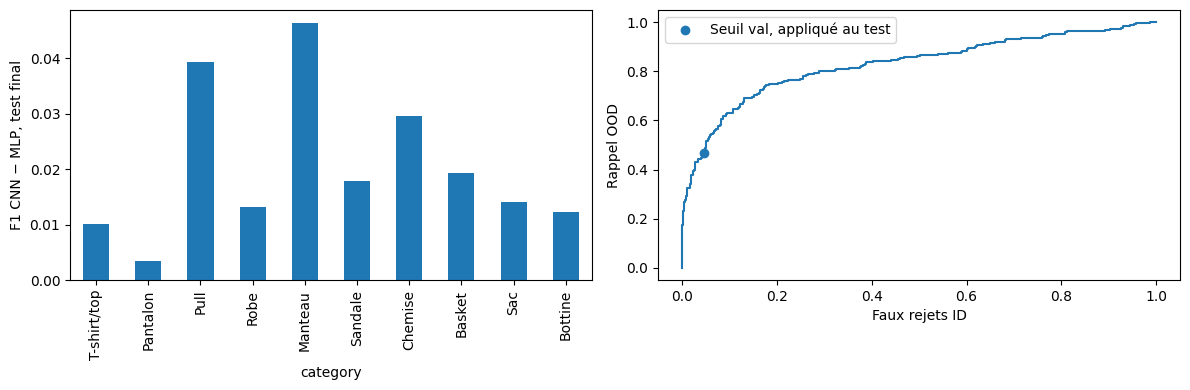

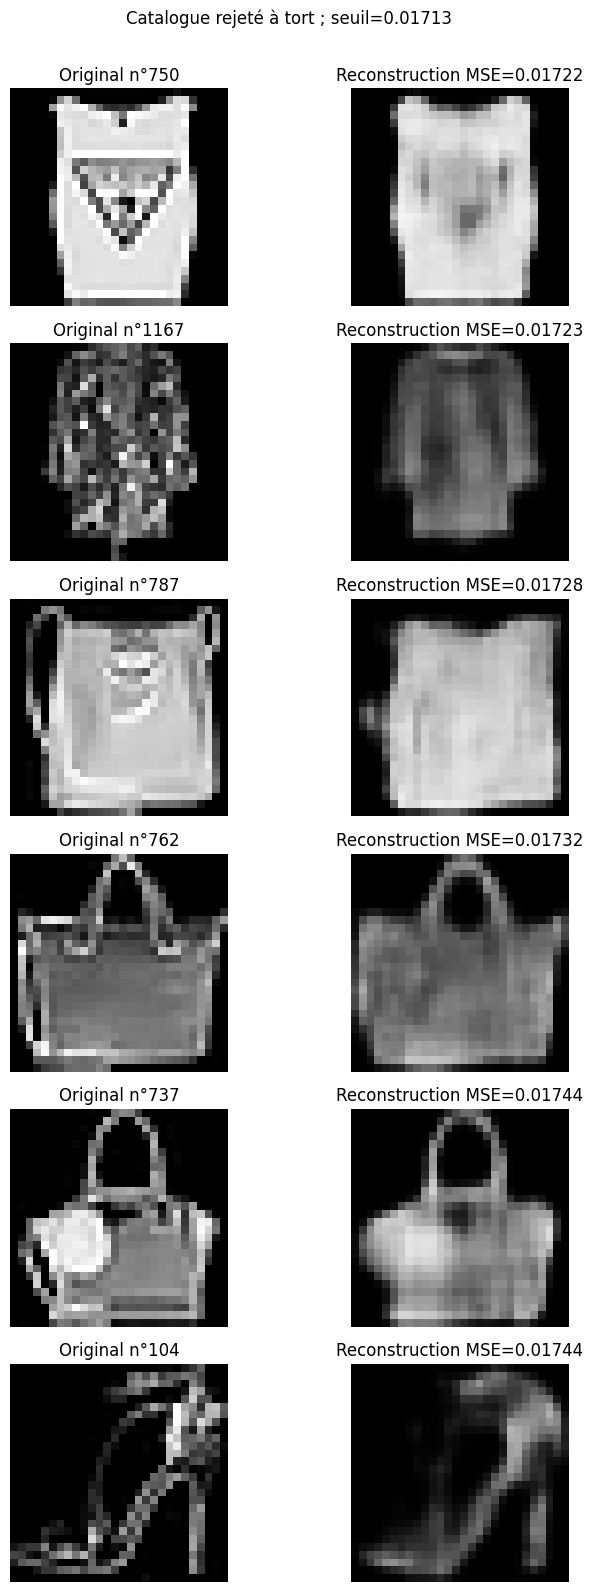

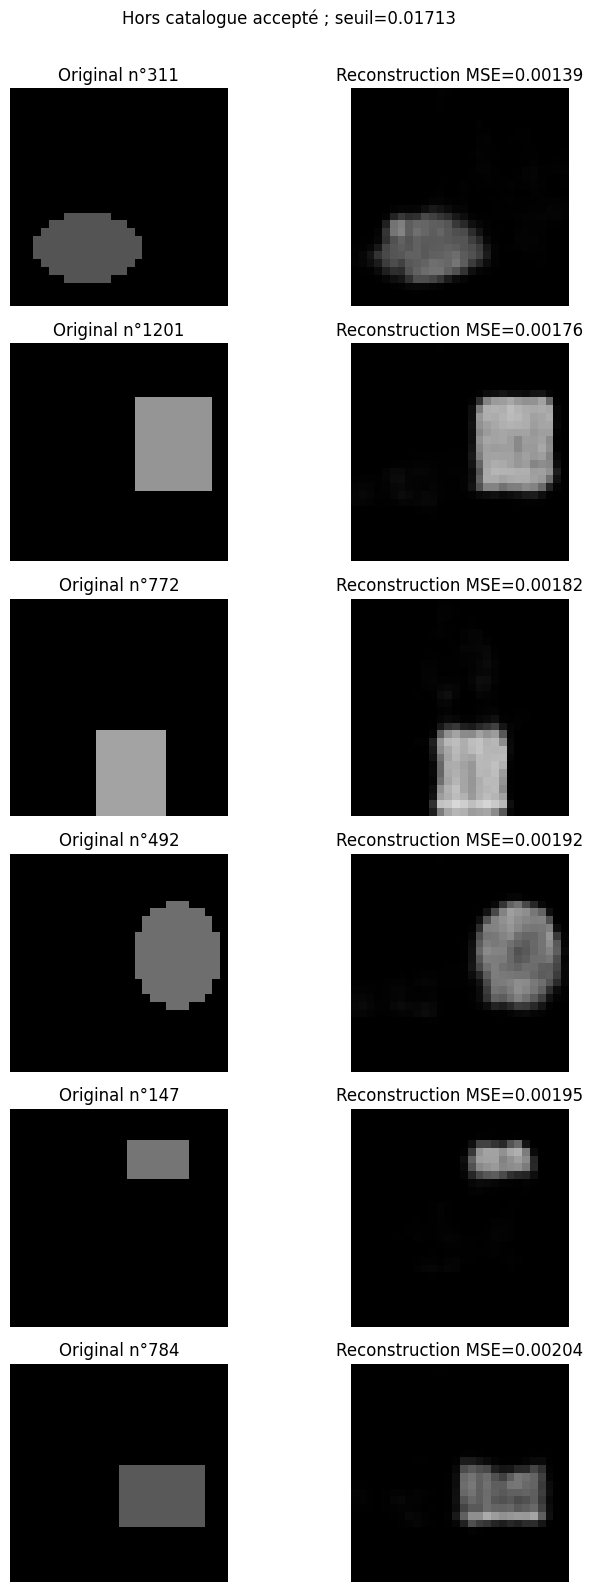

In [7]:
z=np.load(OUT/'test_predictions.npz');show_confusion(z['category_true'],z['cnn_probability'],OUT)
ref=per_class(z['category_true'],z['mlp_probability']);win=per_class(z['category_true'],z['cnn_probability'])
GAIN=ref.rename(columns={'f1':'mlp_f1'});GAIN['cnn_f1']=win.f1;GAIN['gain']=GAIN.cnn_f1-GAIN.mlp_f1
display(GAIN);GAIN.to_csv(OUT/'test_per_class_gains.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4))
GAIN.set_index('category').gain.plot.bar(ax=axes[0]);axes[0].set_ylabel('F1 CNN − MLP, test final')
fpr,tpr,_=roc_curve(z['ood_true'],z['ood_score']);axes[1].plot(fpr,tpr)
d=TEST['detector'];axes[1].scatter([d['test_id_fpr']],[d['recall_at_val5pct']],label='Seuil val, appliqué au test')
axes[1].set(xlabel='Faux rejets ID',ylabel='Rappel OOD');axes[1].legend()
fig.tight_layout();fig.savefig(OUT/'final_gains_and_detection.png',dpi=150);plt.show();plt.close(fig)
with np.load(ROOT/'data_UC2/uc2_ood_test.npz',allow_pickle=False) as o:ox=o['X'][...,None].astype('float32')/255.
kind=np.where((z['ood_true']==0)&(z['ood_score']>THRESHOLD),'false_reject',np.where((z['ood_true']==1)&(z['ood_score']<=THRESHOLD),'accepted_ood','correct'))
gallery_indices=np.unique(np.concatenate([np.flatnonzero(kind==e)[np.argsort(z['ood_score'][kind==e])][:6] for e in ['false_reject','accepted_ood']]))
gallery_path=OUT/'ood_gallery_cache.npz'
weight_sha=sha_file(OUT/'models'/SELECTED_AE/'best.keras')
if not gallery_path.exists():
    np.savez_compressed(gallery_path,indices=gallery_indices,reconstruction=predict(AE_MODELS[SELECTED_AE],ox[gallery_indices]),model_sha=weight_sha)
with np.load(gallery_path) as cache:
    assert cache['model_sha'].item()==weight_sha and np.array_equal(cache['indices'],gallery_indices)
    reconstructions={int(i):x for i,x in zip(cache['indices'],cache['reconstruction'])}
pd.DataFrame({'row':np.arange(1300),'is_ood':z['ood_true'],'mse':z['ood_score'],'threshold':THRESHOLD,'decision':kind}).to_csv(OUT/'all_detection_decisions.csv',index=False)
for error,label in [('false_reject','Catalogue rejeté à tort'),('accepted_ood','Hors catalogue accepté')]:
    idx=np.flatnonzero(kind==error);idx=idx[np.argsort(z['ood_score'][idx])][:6]
    print(label,':',np.sum(kind==error),'cas au total')
    if not len(idx):continue
    fig,axes=plt.subplots(len(idx),2,figsize=(8,2.7*len(idx)),squeeze=False)
    for row,i in enumerate(idx):
        for ax,img in zip(axes[row],[ox[i,...,0],reconstructions[int(i)][...,0]]):ax.imshow(img,cmap='gray',vmin=0,vmax=1);ax.axis('off')
        axes[row,0].set_title(f'Original n°{i}');axes[row,1].set_title(f'Reconstruction MSE={z["ood_score"][i]:.5f}')
    fig.suptitle(label+f' ; seuil={THRESHOLD:.5f}');fig.tight_layout(rect=(0,0,1,.975));fig.savefig(OUT/(error+'_examples.png'),dpi=130);plt.show();plt.close(fig)

### Lecture des erreurs OOD du run livré (10 octobre 2026)
Les anomalies acceptées les moins coûteuses à reconstruire incluent des disques
et rectangles gris sur fond noir (lignes 311, 1201, 772, 492, 147, 784).
Leur MSE va d'environ **0,00139 à 0,00204**, sous le seuil **0,017127**.
Une forme simple occupant peu de pixels reçoit donc un score faible malgré son
absence du catalogue. Les faux rejets proches du seuil incluent des images
légitimes texturées/décorées (750, 1167, 787, 760, 737), ainsi qu'un cas évoquant
une chaussure à brides (104) :
l'auto-encodeur lisse les détails et augmente la MSE. Ce sont des hypothèses
visuelles fondées sur les exemples, sans généralisation à tous les vendeurs.
Le seuil demeure celui de la validation. Augmenter la sensibilité après avoir
vu ces erreurs serait une nouvelle étude sur un autre jeu de validation/test.


In [8]:
decision=f"""# Décisions Jalon 2
Groupe XX, UC2. Agrigah Aya, AARAB Mustapha, Toubani Badr Eddine.

**CNN retenu :** {SELECTED_CNN}, F1 test={TEST['cnn']['macro_f1']:.4f} versus MLP={TEST['mlp_reference']['macro_f1']:.4f}, gain={TEST['cnn']['macro_f1']-TEST['mlp_reference']['macro_f1']:+.4f}. Écart à 0,94={TEST['cnn']['macro_f1']-.94:+.4f}. Les gains par catégorie sont `test_per_class_gains.csv`. L'ajout d'un bloc élargit le RF local de 10 à 22 pixels mais réduit la largeur de la carte aplatie ; vérifier les paramètres réels plutôt que conclure que plus profond est toujours plus gros. Pooling et régularisation restent des résultats à une seule graine.

**AE retenu :** {SELECTED_AE}, goulot choisi sur AUC du proxy validation seulement. Seuil ID95%={THRESHOLD:.8f}. Test réel du fichier fourni : AUC={TEST['detector']['auc']:.4f}, rappel au seuil val-5%={TEST['detector']['recall_at_val5pct']:.4f}, faux rejets ID={TEST['detector']['test_id_fpr']:.4f}. Écart à AUC 0,88={TEST['detector']['auc']-.88:+.4f}. {TEST['detector']['false_rejects']} annonces ID rejetées, {TEST['detector']['accepted_ood']} anomalies acceptées. Le taux test de faux rejets peut dépasser 5% : le seuil n'est pas recalibré sur test.

**Théorie :** image seule Conv2 valid=315 146 paramètres, same=421 642 ; RF local=10, saut=4. AE de départ code=1 568 contre 784 pixels, sans goulot étroit. Les AE denses réduisent le code mais peuvent ajouter des poids. Les unités du code ne sont pas un décompte des paramètres.

**Coût vendeur et limites :** un faux rejet bloque une annonce correcte, exige une nouvelle image ou une revue, et peut retarder une vente. Prévoir recours et contrôle, sans inventer de coût en DH. Les images originales/reconstruites d'erreurs sont intégrées. Les motifs visuels se lisent dans les exemples ; une MSE élevée seule ne prouve pas une anomalie. Proxy OOD synthétique différent du test, une graine, image 28×28, données pédagogiques. Les targets du système final ne sont pas exigées au jalon et les écarts sont affichés.
"""
final_decision(OUT,decision)

Journal : 51 entrées. Modèles, décisions et résultats conservés dans /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2/artifacts/jalon2


# Décisions Jalon 2
Groupe XX, UC2. Agrigah Aya, AARAB Mustapha, Toubani Badr Eddine.

**CNN retenu :** CNN_base, F1 test=0.9522 versus MLP=0.9316, gain=+0.0206. Écart à 0,94=+0.0122. Les gains par catégorie sont `test_per_class_gains.csv`. L'ajout d'un bloc élargit le RF local de 10 à 22 pixels mais réduit la largeur de la carte aplatie ; vérifier les paramètres réels plutôt que conclure que plus profond est toujours plus gros. Pooling et régularisation restent des résultats à une seule graine.

**AE retenu :** AE_128, goulot choisi sur AUC du proxy validation seulement. Seuil ID95%=0.01712747. Test réel du fichier fourni : AUC=0.8287, rappel au seuil val-5%=0.4667, faux rejets ID=0.0460. Écart à AUC 0,88=-0.0513. 46 annonces ID rejetées, 160 anomalies acceptées. Le taux test de faux rejets peut dépasser 5% : le seuil n'est pas recalibré sur test.

**Théorie :** image seule Conv2 valid=315 146 paramètres, same=421 642 ; RF local=10, saut=4. AE de départ code=1 568 contre 784 pixels, sans goulot étroit. Les AE denses réduisent le code mais peuvent ajouter des poids. Les unités du code ne sont pas un décompte des paramètres.

**Coût vendeur et limites :** un faux rejet bloque une annonce correcte, exige une nouvelle image ou une revue, et peut retarder une vente. Prévoir recours et contrôle, sans inventer de coût en DH. Les images originales/reconstruites d'erreurs sont intégrées. Les motifs visuels se lisent dans les exemples ; une MSE élevée seule ne prouve pas une anomalie. Proxy OOD synthétique différent du test, une graine, image 28×28, données pédagogiques. Les targets du système final ne sont pas exigées au jalon et les écarts sont affichés.


## Sources et limites de reproductibilité
 - Fiche UC2 du jalon, `Consignes.pdf` et code de départ fournis par l'enseignant
   (copies dans `sources/enseignant/`). Les NPZ incluent les partitions originales.
 - [Fashion-MNIST, Zalando Research](https://github.com/zalandoresearch/fashion-mnist).
 - [TensorFlow/Keras](https://www.tensorflow.org/guide/keras),
   [transfert et ajustement fin](https://keras.io/guides/transfer_learning/),
   [GRU](https://keras.io/api/layers/recurrent_layers/gru/),
   [masquage](https://www.tensorflow.org/guide/keras/understanding_masking_and_padding).

 Une seule graine ne démontre pas la stabilité sur plusieurs initialisations.
 Le déterminisme dépend aussi des versions et du matériel. Les modèles, leurs
 empreintes, les versions et les prédictions finalisées sont inclus dans la remise.
 Les cibles sont celles du système final du cours ; une cible non atteinte est
 signalée, et ne justifie jamais un réglage sur le test.